# Unsupervised Learning #

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from sklearn.cluster import (KMeans,
                            AgglomerativeClustering)
from scipy.cluster.hierarchy import (dendrogram,
                                    cut_tree)
from ISLP.cluster import compute_linkage                                    

## Principal Components Analysis ##

In [3]:
USArrests = get_rdataset('USArrests').data
USArrests.head(5)

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [4]:
USArrests.mean()

Murder        7.788
Assault     170.760
UrbanPop     65.540
Rape         21.232
dtype: float64

In [5]:
USArrests.var()

Murder        18.970465
Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
dtype: float64

In [6]:
USArrests.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


Os dados estão em escalas distintas, como foi lido no capítulo os dados devem estar padronizados pois o PCA busca a maior variabilidade dos dados para criar os componentes principais, esse dataset tem o `Assault` com a maior escala e variabilidade, com isso as outras colunas comparada a essa seria menos relevante e teria menos informação a ser extraída.

In [9]:
scaler = StandardScaler(with_std=True,
                        with_mean=True)#por padrão esses hiperparâmetros já vem como verdadeiro, está só reforçando para leitura
USArrests_scaled = scaler.fit_transform(USArrests)
pd.DataFrame(USArrests_scaled, columns=USArrests.columns).describe().round(5)

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.00000,50.00000,50.00000
mean,-0.00000,0.00000,-0.00000,0.00000
std,1.01015,1.01015,1.01015,1.01015
min,-1.62069,-1.52436,-2.34066,-1.50255
25%,-0.86114,-0.74861,-0.77045,-0.66402
50%,-0.12478,-0.14255,0.03210,-0.12208
75%,0.80293,0.94836,0.85210,0.53310
max,2.22927,2.01503,1.77678,2.67120


In [10]:
pcaUS = PCA()
pcaUS.fit(USArrests_scaled)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [11]:
pcaUS.mean_

array([-7.10542736e-17,  1.38777878e-16, -4.39648318e-16,  8.59312621e-16])

`Scores` - pontuação dos componentes.

Valores dos dados após a projeção dos componentes principal

In [13]:
scores = pcaUS.transform(USArrests_scaled)
scores[:5]

array([[ 0.98556588, -1.13339238, -0.44426879, -0.15626714],
       [ 1.95013775, -1.07321326,  2.04000333,  0.43858344],
       [ 1.76316354,  0.74595678,  0.05478082,  0.83465292],
       [-0.14142029, -1.11979678,  0.11457369,  0.1828109 ],
       [ 2.52398013,  1.54293399,  0.5985568 ,  0.34199648]])

`Loadings` - Pesos

Peso de cada variável/coluna/preditor para os n componentes principais

*o retorno dos `components_` vem no formato de cada linha ser um componente principal*

In [14]:
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

In [ ]:
pd.DataFrame(pcaUS.components_, 
             index=['PC1', 'PC2', 'PC3', 'PC4'], 
             columns=USArrests.columns)

,Murder,Assault,UrbanPop,Rape
PC1,0.535899,0.583184,0.278191,0.543432
PC2,-0.418181,-0.187986,0.872806,0.167319
PC3,-0.341233,-0.268148,-0.378016,0.817778
PC4,-0.649228,0.743407,-0.133878,-0.089024


In [26]:
print('Vendo de forma transposta como os exemplos do livro')
pd.DataFrame(pcaUS.components_.T, 
             columns=['PC1', 'PC2', 'PC3', 'PC4'], 
             index=USArrests.columns)

Vendo de forma transposta como os exemplos do livro


,PC1,PC2,PC3,PC4
Murder,0.535899,-0.418181,-0.341233,-0.649228
Assault,0.583184,-0.187986,-0.268148,0.743407
UrbanPop,0.278191,0.872806,-0.378016,-0.133878
Rape,0.543432,0.167319,0.817778,-0.089024


In [25]:
print(scores[:5])
print('Calculando a projeção "manualmente" dos dados com os pesos:')
print(USArrests_scaled[:5] @ pcaUS.components_.T)

[[ 0.98556588 -1.13339238 -0.44426879 -0.15626714]
 [ 1.95013775 -1.07321326  2.04000333  0.43858344]
 [ 1.76316354  0.74595678  0.05478082  0.83465292]
 [-0.14142029 -1.11979678  0.11457369  0.1828109 ]
 [ 2.52398013  1.54293399  0.5985568   0.34199648]]
Calculando a projeção "manualmente" dos dados com os pesos:
[[ 0.98556588 -1.13339238 -0.44426879 -0.15626714]
 [ 1.95013775 -1.07321326  2.04000333  0.43858344]
 [ 1.76316354  0.74595678  0.05478082  0.83465292]
 [-0.14142029 -1.11979678  0.11457369  0.1828109 ]
 [ 2.52398013  1.54293399  0.5985568   0.34199648]]


**BIPLOT**

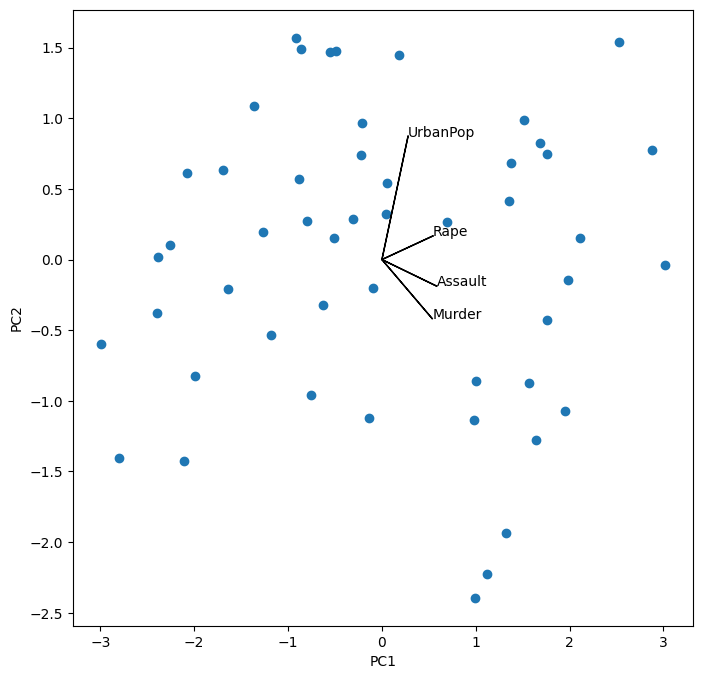

In [29]:
i, j = 0, 1 # componentes selecionados
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(scores[:, i], scores[:, j])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
    ax.arrow(0, 0, pcaUS.components_[i,k], pcaUS.components_[j,k])
    ax.text(pcaUS.components_[i,k],
            pcaUS.components_[j,k],
            USArrests.columns[k])

Invertendo um eixo, vale ressaltar que os valores são únicos porém o sinal pode ser invertido dependendo da forma de calcular, de linguagem ou biblioteca, podemos inverter qualquer um ou todos, importante é quando inverter o loadings/pesos tambem inverter o scores/pontuação dos componentes 

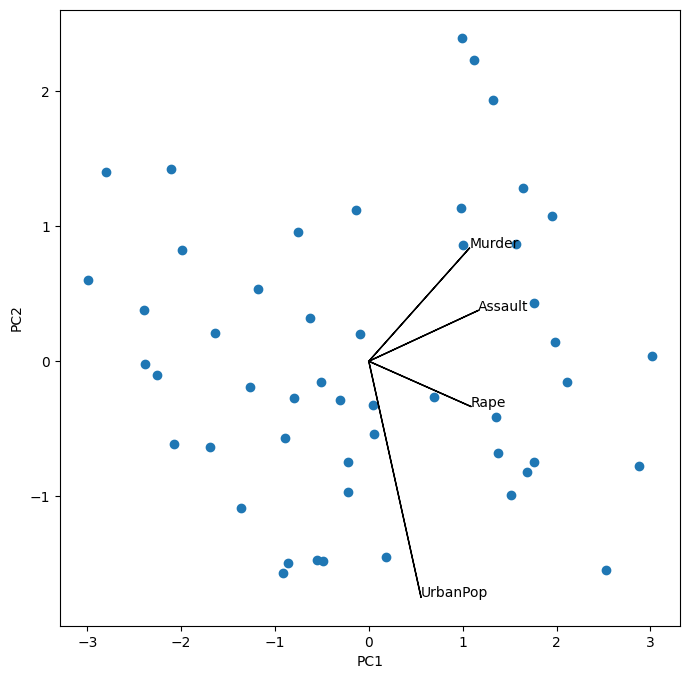

In [30]:
scale_arrow = s_ = 2
scores[:, 1] *= -1
pcaUS.components_[1] *=-1

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(scores[:, i], scores[:, j])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
    ax.arrow(0, 0, s_ * pcaUS.components_[i,k], s_ * pcaUS.components_[j,k])
    ax.text(s_*pcaUS.components_[i,k],
            s_*pcaUS.components_[j,k],
            USArrests.columns[k])

In [32]:
scores.std(0, ddof=1)

array([1.5908673 , 1.00496987, 0.6031915 , 0.4206774 ])

In [33]:
pcaUS.explained_variance_

array([2.53085875, 1.00996444, 0.36383998, 0.17696948])

In [34]:
pcaUS.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

In [35]:
%%capture

fig, axes = plt.subplots(1,2,figsize=(15,6))
ticks = np.arange(pcaUS.n_components_)+1
ax = axes[0]
ax.plot(ticks,
        pcaUS.explained_variance_ratio_,
        marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Proportion of Variance Explained')
ax.set_ylim([0,1])
ax.set_xticks(ticks)


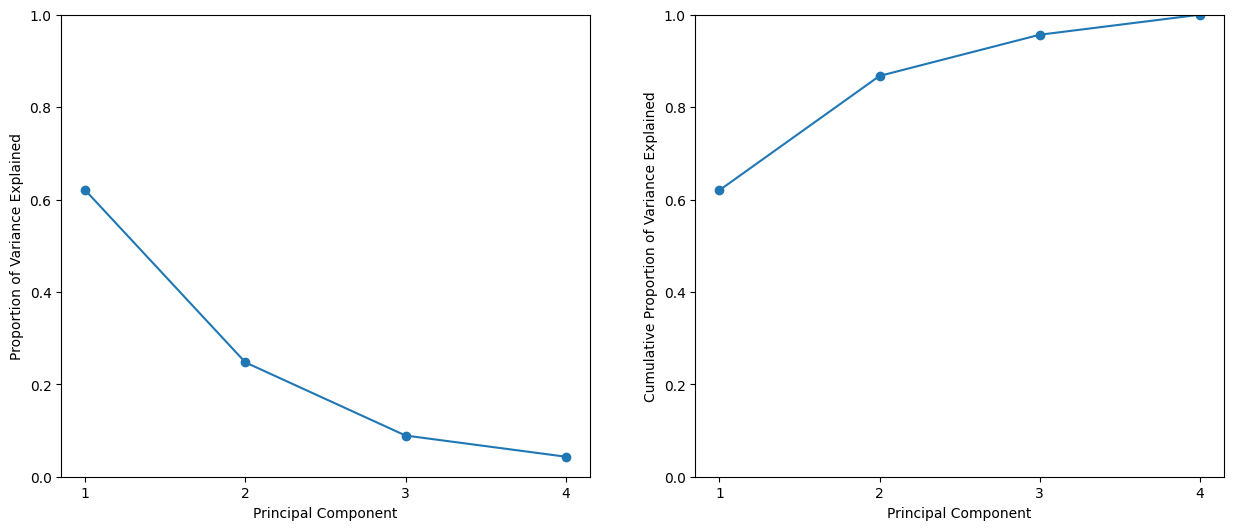

In [36]:
ax=axes[1]
ax.plot(ticks,
        pcaUS.explained_variance_ratio_.cumsum(),
        marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Cumulative Proportion of Variance Explained')
ax.set_ylim([0,1])
ax.set_xticks(ticks)
fig

In [37]:
a = np.array([1,2,8,-3])
np.cumsum(a)

array([ 1,  3, 11,  8])